# Practical 10 – PCA 2D Visualization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
raw = load_wine(as_frame=True)


In [2]:
X = raw.data
y = raw.target
scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2)
coords = pca.fit_transform(scaled)
print('Original:', X.shape, 'Reduced:', coords.shape, 'Explained:', pca.explained_variance_ratio_, 'Total:', sum(pca.explained_variance_ratio_))


Original: (178, 13) Reduced: (178, 2) Explained: [0.36198848 0.1920749 ] Total: 0.554063383569353


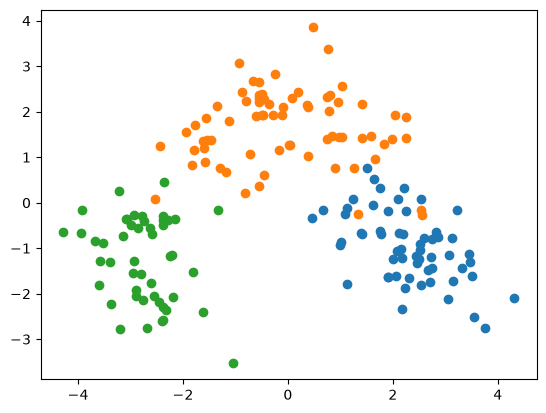

In [3]:
for c in sorted(y.unique()):
    mask = (y == c).to_numpy()
    plt.scatter(coords[mask, 0], coords[mask, 1], label=raw.target_names[c])


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28648\2154005032.py:1: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


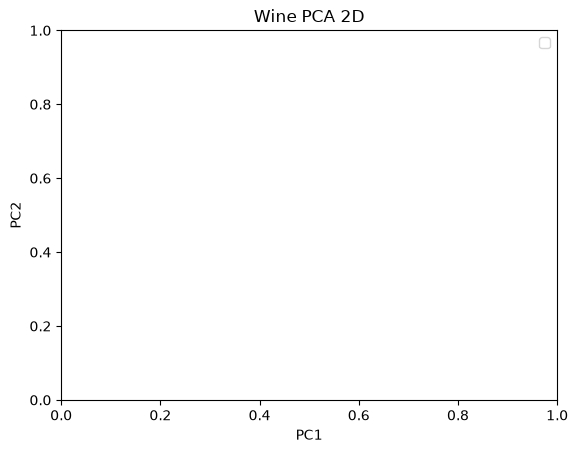

In [6]:
plt.legend()
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Wine PCA 2D')
plt.show()
pd.DataFrame({'PC1': coords[:, 0], 'PC2': coords[:, 1], 'Class': y}).to_csv('wine_pca_2d.csv', index=False)
